# [Lab Session 1](sobel.ipynb)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Load and show the image:

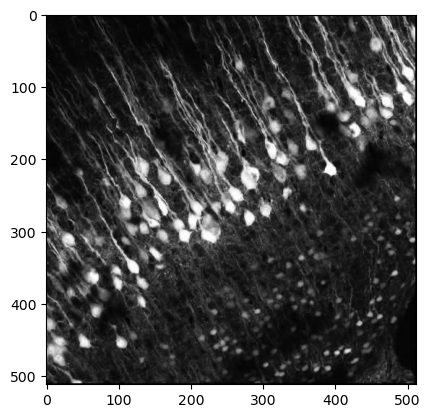

In [12]:
img = plt.imread('data/cells.png')

plt.imshow(img, cmap = 'gray')

**[Task 2.2.]()** Implement the two functions `sobel_h` and `sobel_v` for horizontal and vertical $3 \times 3$ Sobel filtering, respectively:

In [7]:
def sobel_h(img):
    kernel = np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ]) / 8

    img_padded = np.pad(img, 1, mode='symmetric') # padding adds another border of pixels around the image so the filter can be applied at the edges
    result = np.zeros_like(img, dtype=float) # creates an empty array with the size of the padded image

    for i in range(img.shape[0]): #img.shape[0] extracts the number of rows in img.  [1] the number of cols
        for j in range(img.shape[1]):
            region = img_padded[i:i+3, j:j+3]
            result[i, j] = np.sum(region * np.flip(kernel))

    return result


def sobel_v(img):
    kernel = np.array([
        [1, 2, 1],
        [0, 0, 0],
        [-1, -2, -1]
    ]) / 8

    img_padded = np.pad(img, 1, mode='symmetric')
    result = np.zeros_like(img, dtype=float)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = img_padded[i:i+3, j:j+3]
            result[i, j] = np.sum(region * np.flip(kernel))

    return result

**[Task 2.3.]()** Test your implementations from above:

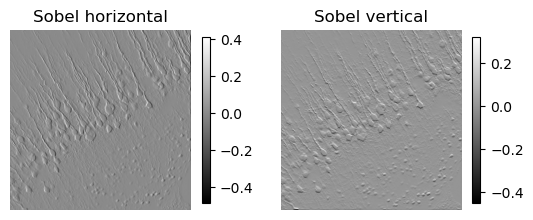

In [20]:
img_sobel_h = sobel_h(img)

img_sobel_v = sobel_v(img)

plt.figure()
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(img_sobel_h, cmap = 'gray')
plt.colorbar(shrink=0.45)
plt.title('Sobel horizontal')

plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(img_sobel_v, cmap = 'gray')
plt.colorbar(shrink=0.45)
plt.title('Sobel vertical')

plt.tight_layout
plt.show()

**[Task 2.4.]()** Compute the image gradient magnitude:

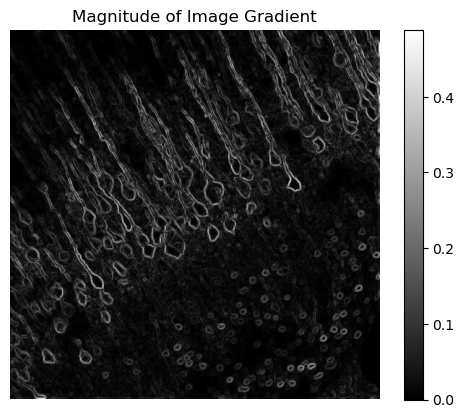

In [23]:
gradient_magnitude = np.sqrt(img_sobel_h**2 + img_sobel_v**2)

plt.figure()

plt.imshow(gradient_magnitude, cmap='gray')
plt.title('Magnitude of Image Gradient')
plt.axis('off')
plt.colorbar()

plt.savefig('gradient_magnitude.png')
plt.show()